# Modelo predictivo de abandono en telecomunicaciones
## Ramírez y Parraguez
Este cuaderno implementa el protocolo del informe: 15 predictores, partición estratificada 80/20, cinco pliegues, seis variantes, selección por AP con tolerancia 0,005, umbral por F1 fuera de pliegue y bootstrap pareado estratificado.

**Alcance:** Telco Customer Churn de IBM. Se trata de clasificación retrospectiva; no acredita anticipación temporal ni efecto causal de campañas.

**Historial:** esta versión corrige un notebook con resultados de prueba ya conocidos. La partición se conserva para trazabilidad. La evaluación corregida es una reevaluación interna, no una validación externa o una nueva prueba confirmatoria independiente. No se ajustarán criterios para favorecer las métricas finales.

Ejecutar las celdas en orden. Se guardan CSV, JSON, gráficos, modelo, dependencias, controles y una copia de la fuente dentro de `resultados_tesis`. Al final se crea un ZIP descargable.

In [2]:
# Instalación únicamente cuando el entorno no dispone de XGBoost.
import importlib.util, subprocess, sys
if importlib.util.find_spec('xgboost') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'xgboost'])

In [3]:
import os, json, hashlib, platform, time, warnings, urllib.request, shutil
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split, ParameterSampler, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
warnings.simplefilter('default')
SEED = 42
N_JOBS = 2  # Limita memoria y evita paralelismo anidado.
OUT = Path('resultados_tesis'); OUT.mkdir(exist_ok=True)
START = datetime.now(timezone.utc).isoformat()
np.random.seed(SEED)
checks = []
def check(case, detail, condition):
    ok = bool(condition)
    checks.append({'caso': case, 'comprobacion': detail, 'estado': 'APROBADO' if ok else 'FALLA'})
    pd.DataFrame(checks).to_csv(OUT/'comprobaciones.csv', index=False)
    if not ok:
        raise AssertionError(f'{case}: {detail}')

def json_save(name, value):
    (OUT/name).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')
versions = {p: metadata.version(p) for p in ['numpy','pandas','scikit-learn','xgboost','joblib','matplotlib']}
json_save('entorno.json', {'python':sys.version, 'plataforma':platform.platform(), 'versiones':versions, 'inicio_utc':START, 'n_jobs':N_JOBS})
(OUT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\n')
print('Entorno:', versions)

Entorno: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'matplotlib': '3.10.0'}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 1 Fuente y comprobaciones de integridad
La descarga procede directamente del repositorio de IBM. Kaggle queda como referencia de distribución del conjunto, pero no como origen de esta descarga. La URL y el SHA-256 permiten identificar los bytes utilizados. Los duplicados idénticos se reducen a una copia; un mismo identificador con registros contradictorios detiene el análisis.

In [4]:
NUM = ['tenure','MonthlyCharges','TotalCharges']
CAT = ['Contract','PhoneService','MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling','PaymentMethod']
FEATURES = NUM + CAT
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
SOURCE = Path('Telco-Customer-Churn.csv')
if not SOURCE.exists():
    urllib.request.urlretrieve(URL, SOURCE)
raw = pd.read_csv(SOURCE)
sha = hashlib.sha256(SOURCE.read_bytes()).hexdigest()

def validate(frame):
    required = set(FEATURES + ['customerID','Churn'])
    if not required.issubset(frame.columns):
        raise ValueError('Faltan columnas: '+str(sorted(required-set(frame.columns))))
    if frame['customerID'].isna().any() or frame['customerID'].astype(str).str.strip().eq('').any():
        raise ValueError('Identificadores faltantes')
    if not frame['Churn'].isin(['Yes','No']).all():
        raise ValueError('Etiqueta Churn inválida')
    unique = frame.drop_duplicates().copy()
    if unique['customerID'].duplicated().any():
        raise ValueError('Identificadores con registros contradictorios')
    return unique

def rejects(frame):
    try: validate(frame)
    except ValueError: return True
    return False

df = validate(raw)
check('CP-01','Esquema y etiquetas válidos', set(FEATURES+['Churn','customerID']).issubset(df.columns))
check('CP-01','Rechaza archivo sin Churn', rejects(raw.drop(columns='Churn')))
bad = raw.iloc[:2].copy(); bad.loc[bad.index[0],'Churn']='INVALIDO'
check('CP-01','Rechaza etiqueta inválida', rejects(bad))
check('CP-02','Reduce duplicado exacto', len(validate(pd.concat([raw,raw.iloc[[0]]])))==len(df))
conflict=raw.iloc[[0]].copy(); conflict['Churn']=np.where(conflict['Churn'].eq('Yes'),'No','Yes')
check('CP-02','Rechaza ID contradictorio', rejects(pd.concat([raw,conflict])))
y=df['Churn'].map({'Yes':1,'No':0}).astype(int)
X=df[FEATURES].copy()
for col in NUM: X[col]=pd.to_numeric(X[col],errors='coerce')
quality={'filas_originales':len(raw),'columnas_originales':len(raw.columns),'filas_analiticas':len(df), 'duplicados_exactos_eliminados':len(raw)-len(df),'ids_duplicados_originales':int(raw.customerID.duplicated().sum()), 'positivos':int(y.sum()),'negativos':int((y==0).sum()),'prevalencia':float(y.mean()),'faltantes_numericos':X[NUM].isna().sum().to_dict(), 'sha256':sha,'url_descarga':URL,'fecha_ejecucion_utc':START}
json_save('calidad_fuente.json',quality)
shutil.copyfile(SOURCE,OUT/'fuente_Telco-Customer-Churn.csv')
print(json.dumps(quality,ensure_ascii=False,indent=2))

{
  "filas_originales": 7043,
  "columnas_originales": 21,
  "filas_analiticas": 7043,
  "duplicados_exactos_eliminados": 0,
  "ids_duplicados_originales": 0,
  "positivos": 1869,
  "negativos": 5174,
  "prevalencia": 0.2653698707936959,
  "faltantes_numericos": {
    "tenure": 0,
    "MonthlyCharges": 0,
    "TotalCharges": 11
  },
  "sha256": "16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91",
  "url_descarga": "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
  "fecha_ejecucion_utc": "2026-10-24T03:36:14.200228+00:00"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
check('CP-02','Sin clientes compartidos entre desarrollo y prueba', not set(df.loc[X_dev.index,'customerID']) & set(df.loc[X_test.index,'customerID']))
repeat=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
check('CP-04','Repite exactamente los índices', np.array_equal(X_dev.index,repeat[0].index) and np.array_equal(X_test.index,repeat[1].index))
splits=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(splits.split(X_dev,y_dev))
for tr,va in folds: check('CP-04','Pliegue sin índices compartidos', len(set(tr)&set(va))==0)
pd.DataFrame({'fila_fuente':X_dev.index,'particion':'desarrollo'}).to_csv(OUT/'indices_desarrollo.csv',index=False)
pd.DataFrame({'fila_fuente':X_test.index,'particion':'prueba'}).to_csv(OUT/'indices_prueba.csv',index=False)
fold_export=[]
for k,(tr,va) in enumerate(folds,1):
    fold_export.extend({'pliegue':k,'fila_fuente':int(X_dev.index[i]),'rol':'validacion'} for i in va)
pd.DataFrame(fold_export).to_csv(OUT/'indices_validacion.csv',index=False)
partition=pd.DataFrame([{'particion':name,'n':len(a),'positivos':int(b.sum()),'negativos':int((b==0).sum()),'prevalencia':b.mean(),'faltantes_TotalCharges':int(a.TotalCharges.isna().sum())} for name,a,b in [('Desarrollo',X_dev,y_dev),('Prueba',X_test,y_test)]])
partition.to_csv(OUT/'particiones.csv',index=False)
print(partition.to_string(index=False))

 particion    n  positivos  negativos  prevalencia  faltantes_TotalCharges
Desarrollo 5634       1495       4139     0.265353                       8
    Prueba 1409        374       1035     0.265436                       3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 2 Preprocesamiento y ponderación por pliegue
El módulo auxiliar se escribe junto al modelo para permitir su recarga. XGBoost calcula el peso a partir de las etiquetas recibidas por cada `fit`. Los modelos de cada pliegue se conservan temporalmente para verificar su peso y las medianas aprendidas, y luego se liberan.

In [6]:
MODULE = "from sklearn.base import BaseEstimator, ClassifierMixin\nimport numpy as np\nfrom xgboost import XGBClassifier\nclass FoldWeightedXGB(ClassifierMixin, BaseEstimator):\n    def __init__(self, weighted=False, n_estimators=200, max_depth=3, learning_rate=0.1, subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0, random_state=42, n_jobs=1):\n        self.weighted=weighted\n        self.n_estimators=n_estimators\n        self.max_depth=max_depth\n        self.learning_rate=learning_rate\n        self.subsample=subsample\n        self.colsample_bytree=colsample_bytree\n        self.reg_lambda=reg_lambda\n        self.random_state=random_state\n        self.n_jobs=n_jobs\n    def fit(self,X,y):\n        a=np.asarray(y)\n        pos=int((a==1).sum()); neg=int((a==0).sum())\n        if not pos or not neg: raise ValueError('Se requieren ambas clases')\n        self.scale_pos_weight_=neg/pos if self.weighted else 1.0\n        self.model_=XGBClassifier(n_estimators=self.n_estimators,max_depth=self.max_depth,learning_rate=self.learning_rate,subsample=self.subsample,colsample_bytree=self.colsample_bytree,reg_lambda=self.reg_lambda,random_state=self.random_state,n_jobs=self.n_jobs,scale_pos_weight=self.scale_pos_weight_,objective='binary:logistic',eval_metric='logloss',tree_method='hist')\n        self.model_.fit(X,y)\n        self.classes_=self.model_.classes_\n        self.n_features_in_=self.model_.n_features_in_\n        return self\n    def predict_proba(self,X): return self.model_.predict_proba(X)\n    def predict(self,X): return self.model_.predict(X)\n"
(OUT/'churn_estimators.py').write_text(MODULE,encoding='utf-8')
sys.path.insert(0,str(OUT.resolve()))
from churn_estimators import FoldWeightedXGB

In [7]:
def preprocessor(scale):
    numeric=[('imputer',SimpleImputer(strategy='median'))]
    if scale: numeric.append(('scaler',StandardScaler()))
    return ColumnTransformer([('num',Pipeline(numeric),NUM),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT)])
prep_check=preprocessor(True)
transformed=prep_check.fit_transform(X_dev)
check('CP-03','Matriz de desarrollo finita', np.isfinite(transformed).all())
check('CP-03','Medianas ajustadas con desarrollo', np.allclose(prep_check.named_transformers_['num'].named_steps['imputer'].statistics_,X_dev[NUM].median().values))
probe=X_dev.iloc[:2].copy();probe.loc[probe.index[0],'TotalCharges']=np.nan
check('CP-03','Imputa faltantes en entrada',np.isfinite(prep_check.transform(probe)).all())
probe.loc[probe.index[0],'Contract']='CATEGORIA_NO_OBSERVADA'
a=prep_check.transform(probe)
check('CP-10','Categoría nueva admitida sin cambiar dimensiones',a.shape[1]==transformed.shape[1] and np.isfinite(a).all())
print('Predictores originales:',len(FEATURES),'Columnas transformadas:',transformed.shape[1],'Valores no finitos:',int((~np.isfinite(transformed)).sum()))
quality['columnas_transformadas_desarrollo']=int(transformed.shape[1]);json_save('calidad_fuente.json',quality)

Predictores originales: 15 Columnas transformadas: 38 Valores no finitos: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 3 Búsqueda y selección por validación
Regresión logística: 6 valores de C por variante. Random Forest y XGBoost: 15 combinaciones por variante, sin repetición y usando las mismas combinaciones para comparar ponderaciones.

La regla se aplica a todas las configuraciones supervisadas evaluadas: candidatos cuya AP esté a no más de 0,005 del máximo; se prefiere menor desviación estándar y, si hay igualdad, regresión logística, Random Forest y XGBoost, en ese orden. Un índice estable resuelve cualquier empate residual. Se usan cifras sin redondear. El resumen por variante muestra su configuración de máxima AP; no sustituye la regla de selección global.

In [8]:
spaces={
'LR':{'clf__C':[.001,.01,.1,1.,10.,100.]},
'RF':{'clf__n_estimators':[200,400],'clf__max_depth':[None,8,16],'clf__min_samples_leaf':[1,3,5],'clf__max_features':['sqrt',.7]},
'XGB':{'clf__n_estimators':[200,400],'clf__max_depth':[2,3,5],'clf__learning_rate':[.03,.1],'clf__subsample':[.8,1.],'clf__colsample_bytree':[.8,1.],'clf__reg_lambda':[1.,5.]}}
configs={key:list(ParameterSampler(space,n_iter=6 if key=='LR' else 15,random_state=SEED)) for key,space in spaces.items()}
variants=[]
for family in ['LR','RF','XGB']:
    for weighted in [False,True]:
        if family=='LR': estimator=LogisticRegression(C=1.,solver='lbfgs',max_iter=3000,class_weight='balanced' if weighted else None,random_state=SEED)
        elif family=='RF':estimator=RandomForestClassifier(class_weight='balanced' if weighted else None,random_state=SEED,n_jobs=1)
        else:estimator=FoldWeightedXGB(weighted=weighted,random_state=SEED,n_jobs=1)
        variants.append((family,weighted,Pipeline([('prep',preprocessor(family=='LR')),('clf',estimator)])))
json_save('protocolo_congelado.json',{'semilla':SEED,'test_size':.2,'pliegues':5,'tolerancia_ap':.005,'seleccion':'banda respecto al máximo; menor DE; orden LR RF XGB; índice estable','espacios':spaces,'configuraciones':configs,'permutaciones':30,'bootstrap':2000,'umbral':'todos los scores OOF distintos; máximo F1; empate umbral mayor','fecha_utc':datetime.now(timezone.utc).isoformat(),'estado_prueba':'partición conocida en versión anterior'})
records=[]; candidates={}; fold_rows=[]; fit_audit=[]
for family,weighted,pipe in variants:
    name=family+(' ponderado' if weighted else ' sin ponderar')
    for params in configs[family]:
        candidate=clone(pipe).set_params(**params)
        start=time.perf_counter()
        with joblib.parallel_backend('threading'):
            cvout=cross_validate(candidate,X_dev,y_dev,cv=folds,scoring={'AP':'average_precision','ROC_AUC':'roc_auc'},n_jobs=N_JOBS,error_score='raise',return_estimator=True)
        cid=len(records);candidates[cid]=candidate
        for k,((tr,va),est) in enumerate(zip(folds,cvout['estimator']),1):
            med=est.named_steps['prep'].named_transformers_['num'].named_steps['imputer'].statistics_
            assert np.allclose(med,X_dev.iloc[tr][NUM].median().values), 'Mediana fuera del pliegue'
            weight=None
            if family=='XGB':
                expected=float((y_dev.iloc[tr]==0).sum()/(y_dev.iloc[tr]==1).sum()) if weighted else 1.
                weight=float(est.named_steps['clf'].scale_pos_weight_)
                assert np.isclose(weight,expected), 'Peso fuera del pliegue'
            fit_audit.append({'id':cid,'pliegue':k,'n_entrenamiento':len(tr),'medianas':med.tolist(),'peso_xgb':weight,'sin_interseccion':len(set(tr)&set(va))==0})
            fold_rows.append({'id':cid,'variante':name,'pliegue':k,'AP':float(cvout['test_AP'][k-1]),'ROC_AUC':float(cvout['test_ROC_AUC'][k-1])})
        records.append({'id':cid,'familia':family,'variante':name,'ponderado':weighted,'AP_media':float(np.mean(cvout['test_AP'])),'AP_DE':float(np.std(cvout['test_AP'])),'ROC_AUC_media':float(np.mean(cvout['test_ROC_AUC'])),'segundos':time.perf_counter()-start,'parametros':json.dumps(params,sort_keys=True)})
        del cvout
    print(name,'completado',flush=True)
results=pd.DataFrame(records)
results.to_csv(OUT/'busqueda_completa.csv',index=False)
pd.DataFrame(fold_rows).to_csv(OUT/'metricas_por_pliegue.csv',index=False)
json_save('auditoria_fit_pliegues.json',fit_audit)
check('CP-04','Imputación verificada en cada fit de validación',len(fit_audit)==len(results)*5)
check('CP-09','Seis variantes y pesos verificados por pliegue',results.variante.nunique()==6)
check('CP-05','Tres familias con métricas CV finitas',results.familia.nunique()==3 and np.isfinite(results[['AP_media','ROC_AUC_media']]).all().all())
summary=results.loc[results.groupby('variante',sort=False).AP_media.idxmax()].copy()
summary.to_csv(OUT/'resumen_variantes.csv',index=False)
max_ap=results.AP_media.max()
eligible=results.loc[results.AP_media>=max_ap-.005].copy()
eligible['orden_familia']=eligible.familia.map({'LR':0,'RF':1,'XGB':2})
selected=eligible.sort_values(['AP_DE','orden_familia','id']).iloc[0]
winner=clone(candidates[int(selected.id)])
json_save('seleccion_modelo.json',{'seleccionado':selected.to_dict(),'max_AP_observada':float(max_ap),'candidatos_en_banda':len(eligible),'congelado_utc':datetime.now(timezone.utc).isoformat()})
print(summary[['variante','AP_media','AP_DE','ROC_AUC_media']].to_string(index=False))
print('SELECCIONADO POR REGLA COMPLETA:',selected.variante,'AP:',selected.AP_media,'DE:',selected.AP_DE,'parámetros:',selected.parametros)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are

LR sin ponderar completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

LR ponderado completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

RF sin ponderar completado


... (3 outputs left out)

XGB sin ponderar completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


XGB ponderado completado
        variante  AP_media    AP_DE  ROC_AUC_media
 LR sin ponderar  0.659948 0.018356       0.846027
    LR ponderado  0.658041 0.018947       0.845836
 RF sin ponderar  0.665567 0.019725       0.848097
    RF ponderado  0.665352 0.019834       0.844615
XGB sin ponderar  0.671199 0.021396       0.850184
   XGB ponderado  0.670085 0.021067       0.849572
SELECCIONADO POR REGLA COMPLETA: XGB sin ponderar AP: 0.6679452900333518 DE: 0.01990789951895294 parámetros: {"clf__colsample_bytree": 0.8, "clf__learning_rate": 0.03, "clf__max_depth": 5, "clf__n_estimators": 200, "clf__reg_lambda": 5.0, "clf__subsample": 0.8}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [10]:
# OOF para fijar umbral. No es una evaluación externa: la búsqueda usó desarrollo.
with joblib.parallel_backend('threading'):
    oof=cross_val_predict(winner,X_dev,y_dev,cv=folds,method='predict_proba',n_jobs=N_JOBS)[:,1]
prec,rec,thresholds=precision_recall_curve(y_dev,oof)
f1_candidates=np.divide(2*prec[:-1]*rec[:-1],prec[:-1]+rec[:-1],out=np.zeros(len(thresholds)),where=(prec[:-1]+rec[:-1])!=0)
max_f1=f1_candidates.max()
ties=np.flatnonzero(np.isclose(f1_candidates,max_f1,rtol=0,atol=1e-12))
threshold=float(thresholds[ties[-1]])
check('CP-11','Todos los registros tienen una predicción OOF y umbral válido',len(oof)==len(y_dev) and np.isfinite(oof).all() and 0<=threshold<=1)
pd.DataFrame({'fila_fuente':X_dev.index,'y':y_dev.values,'score_oof':oof}).to_csv(OUT/'predicciones_oof.csv',index=False)
pd.DataFrame({'umbral':thresholds,'F1':f1_candidates}).to_csv(OUT/'busqueda_umbral.csv',index=False)
json_save('umbral_congelado.json',{'umbral':threshold,'F1_oof_desarrollo':float(max_f1),'empates':len(ties),'fecha_utc':datetime.now(timezone.utc).isoformat()})
print('Umbral:',threshold,'F1 OOF de desarrollo:',max_f1)
winner.fit(X_dev,y_dev)
baseline=Pipeline([('prep',preprocessor(False)),('clf',DummyClassifier(strategy='prior'))]).fit(X_dev,y_dev)
scores=winner.predict_proba(X_test)[:,1];pred=(scores>=threshold).astype(int)
base_scores=baseline.predict_proba(X_test)[:,1];base_pred=baseline.predict(X_test)
check('CP-05','Una predicción finita entre 0 y 1 por fila',len(scores)==len(X_test) and np.isfinite(scores).all() and ((scores>=0)&(scores<=1)).all())
check('CP-06','Referencia constante e igual al prior de desarrollo',np.allclose(base_scores,y_dev.mean()))
def metrics(y,score,pred):
    return {'AP':average_precision_score(y,score),'ROC_AUC':roc_auc_score(y,score),'Exactitud':accuracy_score(y,pred),'Precision':precision_score(y,pred,zero_division=0),'Recall':recall_score(y,pred,zero_division=0),'F1':f1_score(y,pred,zero_division=0)}
m=metrics(y_test,scores,pred);mb=metrics(y_test,base_scores,base_pred)
comparison=pd.DataFrame([{'modelo':'Referencia',**mb},{'modelo':selected.variante,**m}])
comparison.to_csv(OUT/'metricas_prueba.csv',index=False)
pd.DataFrame({'fila_fuente':X_test.index,'y':y_test.values,'score_modelo':scores,'prediccion':pred,'score_referencia':base_scores,'prediccion_referencia':base_pred}).to_csv(OUT/'predicciones_prueba.csv',index=False)
check('CP-07','Seis métricas finitas por modelo',np.isfinite(comparison.drop(columns='modelo')).all().all())
print(comparison.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Umbral: 0.3018631935119629 F1 OOF de desarrollo: 0.6352413019079686
          modelo       AP  ROC_AUC  Exactitud  Precision   Recall       F1
      Referencia 0.265436 0.500000   0.734564   0.000000 0.000000 0.000000
XGB sin ponderar 0.660710 0.846339   0.762952   0.537879 0.759358 0.629712


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [11]:
rng=np.random.RandomState(SEED)
y_array=y_test.to_numpy();pos=np.flatnonzero(y_array==1);neg=np.flatnonzero(y_array==0)
deltas=[]
for _ in range(2000):
    ids=np.r_[rng.choice(pos,len(pos),replace=True),rng.choice(neg,len(neg),replace=True)]
    deltas.append(average_precision_score(y_array[ids],scores[ids])-average_precision_score(y_array[ids],base_scores[ids]))
lo,hi=np.percentile(deltas,[2.5,97.5]);delta=m['AP']-mb['AP']
stat_decision='Evidencia de ΔAP > 0 en esta reevaluación interna' if lo>0 else 'No se rechaza H0 en esta reevaluación interna'
check('CP-07','Intervalo finito y 2000 remuestras',len(deltas)==2000 and np.isfinite([lo,hi]).all())
pd.DataFrame({'delta_AP':deltas}).to_csv(OUT/'bootstrap_delta_AP.csv',index=False)
bootstrap={'delta_AP':delta,'IC95_inferior':float(lo),'IC95_superior':float(hi),'decision_condicional':stat_decision,'n_remuestras':2000,'nota':'Intervalo condicionado al modelo y composición de prueba. Partición ya conocida: no constituye confirmación independiente.'}
json_save('bootstrap_resumen.json',bootstrap)
print(json.dumps(bootstrap,ensure_ascii=False,indent=2))
cm=confusion_matrix(y_test,pred,labels=[0,1]);tn,fp,fn,tp=map(int,cm.ravel())
json_save('matriz_confusion.json',{'VN':tn,'FP':fp,'FN':fn,'VP':tp})
print('Matriz de confusión:',cm,sep='\n')
errors=X_test.copy();errors['grupo']=np.select([(y_test==1)&(pred==1),(y_test==1)&(pred==0),(y_test==0)&(pred==1)],['VP','FN','FP'],default='VN')
profile=errors.groupby('grupo').agg(casos=('tenure','size'),antiguedad_mediana=('tenure','median'),cargo_mediana=('MonthlyCharges','median'),contrato_mensual_pct=('Contract',lambda s:100*s.eq('Month-to-month').mean()))
profile.to_csv(OUT/'perfil_errores.csv')
print(profile.to_string())

{
  "delta_AP": 0.39527358306527555,
  "IC95_inferior": 0.35270388113897566,
  "IC95_superior": 0.4390724284884555,
  "decision_condicional": "Evidencia de ΔAP > 0 en esta reevaluación interna",
  "n_remuestras": 2000,
  "nota": "Intervalo condicionado al modelo y composición de prueba. Partición ya conocida: no constituye confirmación independiente."
}
Matriz de confusión:
[[791 244]
 [ 90 284]]
       casos  antiguedad_mediana  cargo_mediana  contrato_mensual_pct
grupo                                                                
FN        90                31.5         66.375             53.333333
FP       244                12.0         79.225             94.672131
VN       791                48.0         56.300             26.927939
VP       284                 4.0         77.750             98.943662


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [12]:
# Interpretación posterior al congelamiento; no se reentrena según estos resultados.
with joblib.parallel_backend('threading'):
    imp=permutation_importance(winner,X_test,y_test,scoring='average_precision',n_repeats=30,random_state=SEED,n_jobs=N_JOBS)
importance=pd.DataFrame({'variable':FEATURES,'caida_AP_media':imp.importances_mean,'DE':imp.importances_std}).sort_values('caida_AP_media',ascending=False)
importance.to_csv(OUT/'importancia_variables.csv',index=False)
print(importance.to_string(index=False))
joblib.dump(winner,OUT/'modelo_churn.joblib')
reloaded=joblib.load(OUT/'modelo_churn.joblib')
error_max=float(np.max(np.abs(scores-reloaded.predict_proba(X_test)[:,1])))
check('CP-08','Recarga con diferencia absoluta <= 1e-8',np.allclose(scores,reloaded.predict_proba(X_test)[:,1],atol=1e-8,rtol=0))
json_save('serializacion.json',{'error_absoluto_maximo':error_max,'tolerancia_absoluta':1e-8,'tolerancia_relativa':0})
print('Diferencia máxima tras recarga:',error_max)

        variable  caida_AP_media       DE
          tenure        0.107960 0.013772
        Contract        0.097185 0.010699
    TotalCharges        0.035473 0.006884
     TechSupport        0.023060 0.006757
 InternetService        0.021830 0.009443
  OnlineSecurity        0.019461 0.006512
  MonthlyCharges        0.011299 0.010192
PaperlessBilling        0.008556 0.008309
   PaymentMethod        0.008082 0.003912
    OnlineBackup        0.004545 0.002607
 StreamingMovies        0.003140 0.002510
   MultipleLines        0.002596 0.005454
    PhoneService        0.002213 0.000659
DeviceProtection       -0.000472 0.000482
     StreamingTV       -0.001527 0.001339
Diferencia máxima tras recarga: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


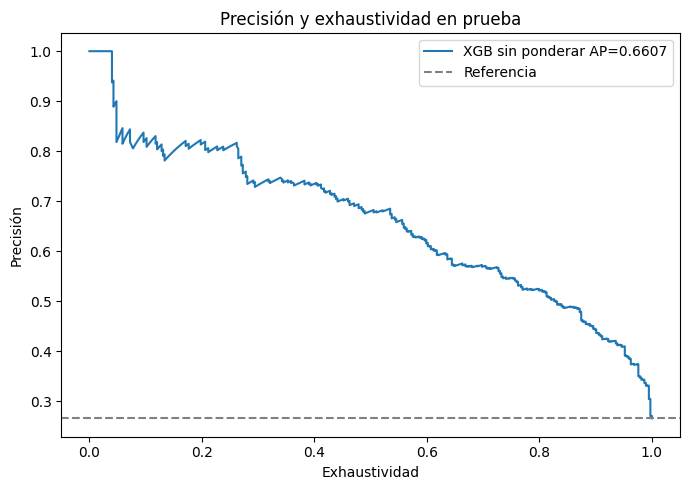

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


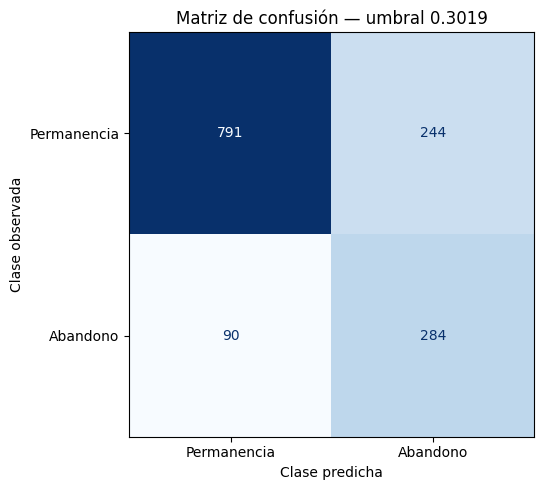

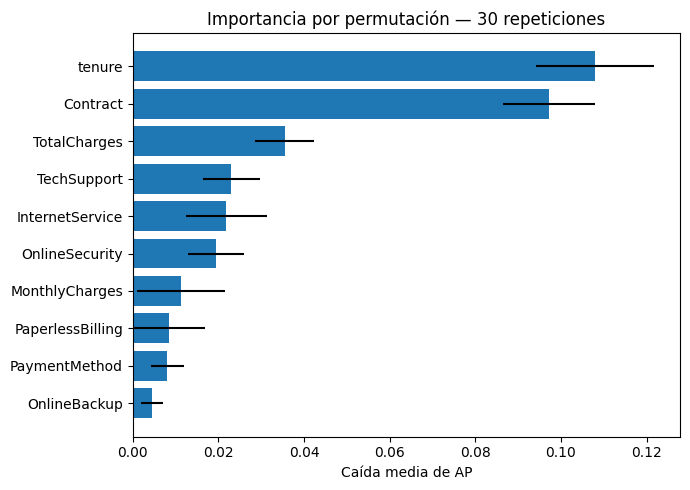

In [13]:
p,r,_=precision_recall_curve(y_test,scores)
plt.figure(figsize=(7,5));plt.plot(r,p,label=f'{selected.variante} AP={m["AP"]:.4f}');plt.axhline(mb['AP'],linestyle='--',color='gray',label='Referencia');plt.xlabel('Exhaustividad');plt.ylabel('Precisión');plt.title('Precisión y exhaustividad en prueba');plt.legend();plt.tight_layout();plt.savefig(OUT/'curva_precision_exhaustividad.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=['Permanencia','Abandono']).plot(ax=ax,colorbar=False,cmap='Blues');ax.set_xlabel('Clase predicha');ax.set_ylabel('Clase observada');ax.set_title(f'Matriz de confusión — umbral {threshold:.4f}');plt.tight_layout();plt.savefig(OUT/'matriz_confusion.png',dpi=160);plt.show()
top=importance.head(10).sort_values('caida_AP_media');plt.figure(figsize=(7,5));plt.barh(top.variable,top.caida_AP_media,xerr=top.DE);plt.xlabel('Caída media de AP');plt.title('Importancia por permutación — 30 repeticiones');plt.tight_layout();plt.savefig(OUT/'importancia_variables.png',dpi=160);plt.show()

In [14]:
# === Casos de prueba ===
# CP-13 (RNF-02): tiempo de ejecución | CP-14 (RNF-01): reproducibilidad | CP-15 (RF-09): importancia
def registrar(case, detail, condition):
    # Igual que check(), pero NO detiene el notebook si falla: la falla queda documentada.
    ok = bool(condition)
    checks.append({'caso': case, 'comprobacion': detail, 'estado': 'APROBADO' if ok else 'FALLA'})
    pd.DataFrame(checks).to_csv(OUT/'comprobaciones.csv', index=False)
    print(('APROBADO' if ok else 'FALLA'), case, '-', detail)

duracion = (datetime.now(timezone.utc) - datetime.fromisoformat(START)).total_seconds()
registrar('CP-13', f'Ejecución completa en menos de 600 s (obtenido: {duracion:.1f} s)', duracion < 600)

HASH_PRUEBA_REF = 'a913d7336d00dac6936dddbf10d62cfccf7667b0538efa63a224b00c85d8afcb'
HASH_DESARROLLO_REF = '554a1012d9ddc934b1c7af1ab6d848b0fddca772c16eff4e86ea37b8c360c5fe'
METRICAS_REF = {'AP': 0.6607, 'ROC_AUC': 0.8463, 'Exactitud': 0.7630, 'Precision': 0.5379, 'Recall': 0.7594, 'F1': 0.6297}
hash_prueba = hashlib.sha256(','.join(map(str, X_test.index)).encode()).hexdigest()
hash_desarrollo = hashlib.sha256(','.join(map(str, X_dev.index)).encode()).hexdigest()
registrar('CP-14', 'Mismos índices de prueba que la ejecución de referencia', hash_prueba == HASH_PRUEBA_REF)
registrar('CP-14', 'Mismos índices de desarrollo que la ejecución de referencia', hash_desarrollo == HASH_DESARROLLO_REF)
iguales = {k: abs(round(float(m[k]), 4) - v) < 1e-9 for k, v in METRICAS_REF.items()}
registrar('CP-14', 'Métricas de prueba iguales con 4 decimales', all(iguales.values()))

registrar('CP-15', 'Importancia de las 15 variables con media y DE finitas (30 repeticiones)',
          len(importance) == 15 and np.isfinite(importance[['caida_AP_media', 'DE']]).all().all())

json_save('casos_agregados.json', {'duracion_segundos': duracion, 'hash_indices_prueba': hash_prueba,
          'hash_indices_desarrollo': hash_desarrollo, 'metricas_obtenidas': {k: float(m[k]) for k in METRICAS_REF},
          'metricas_iguales_4_decimales': iguales, 'fecha_utc': datetime.now(timezone.utc).isoformat()})

APROBADO CP-13 - Ejecución completa en menos de 600 s (obtenido: 424.9 s)
APROBADO CP-14 - Mismos índices de prueba que la ejecución de referencia
APROBADO CP-14 - Mismos índices de desarrollo que la ejecución de referencia
APROBADO CP-14 - Métricas de prueba iguales con 4 decimales
APROBADO CP-15 - Importancia de las 15 variables con media y DE finitas (30 repeticiones)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [15]:
required=['entorno.json','requirements.txt','calidad_fuente.json','indices_desarrollo.csv','indices_prueba.csv','auditoria_fit_pliegues.json','protocolo_congelado.json','seleccion_modelo.json','umbral_congelado.json','metricas_prueba.csv','predicciones_prueba.csv','bootstrap_resumen.json','modelo_churn.joblib','churn_estimators.py']
check('CP-12','Paquete de evidencia y exclusión de identificadores',all((OUT/f).is_file() for f in required) and 'customerID' not in FEATURES and 'Churn' not in FEATURES)
check('CP-12','Huella de copia coincide con fuente',hashlib.sha256((OUT/'fuente_Telco-Customer-Churn.csv').read_bytes()).hexdigest()==sha)
status=pd.DataFrame(checks).groupby('caso').agg(comprobaciones=('estado','size'),aprobadas=('estado',lambda s:int(s.eq('APROBADO').sum())))
status['estado']=np.where(status.comprobaciones==status.aprobadas,'APROBADO','FALLA')
status.to_csv(OUT/'resumen_pruebas.csv')
print(status.to_string())
json_save('resumen_ejecucion.json',{'inicio_utc':START,'fin_utc':datetime.now(timezone.utc).isoformat(),'modelo':selected.to_dict(),'umbral':threshold,'metricas':m,'referencia':mb,'bootstrap':bootstrap,'matriz_confusion':{'VN':tn,'FP':fp,'FN':fn,'VP':tp},'calidad':quality,'n_casos_aprobados':int(status.estado.eq('APROBADO').sum()),'n_casos':len(status),'total_comprobaciones':len(checks),'error_recarga':error_max})
(OUT/'LEEME.txt').write_text('Ejecución corregida sobre partición ya conocida. No es validación externa. Para recargar el modelo, añadir esta carpeta a sys.path e instalar requirements.txt. No cargar archivos joblib de fuentes desconocidas. Las filas se identifican por índice de origen; los resultados no se interpretan como efectos causales.\n',encoding='utf-8')
manifest={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.iterdir() if p.is_file() and p.name!='manifiesto_sha256.json'}
json_save('manifiesto_sha256.json',manifest)
archive=shutil.make_archive('Evidencias_ModeloPredictivoTesis','zip',root_dir=OUT)
print('Paquete generado:',archive)

       comprobaciones  aprobadas    estado
caso                                      
CP-01               3          3  APROBADO
CP-02               3          3  APROBADO
CP-03               3          3  APROBADO
CP-04               7          7  APROBADO
CP-05               2          2  APROBADO
CP-06               1          1  APROBADO
CP-07               2          2  APROBADO
CP-08               1          1  APROBADO
CP-09               1          1  APROBADO
CP-10               1          1  APROBADO
CP-11               1          1  APROBADO
CP-12               2          2  APROBADO
CP-13               1          1  APROBADO
CP-14               3          3  APROBADO
CP-15               1          1  APROBADO
Paquete generado: /content/Evidencias_ModeloPredictivoTesis.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [16]:
!python --version
!pip freeze | grep -iE "^(numpy|pandas|scikit-learn|xgboost|joblib|matplotlib)=="

Python 3.13.16
joblib==1.6.0
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
xgboost==3.4.1
